# Neural networks

Every experiment with **neural networks** from the archived notebooks, run again on the base data and the common train / validation / test blocks, plus the network experiments that the last run of `classical-models.ipynb` points to.

This notebook is the companion of `classical-models.ipynb`. It uses the same data (`data/btc_hourly.csv.gz`, 76,851 consecutive hours, 1 Jan 2018 → 8 Oct 2026), features, forecast origins, blocks, metrics and baselines, so every network can be compared with a classical model on the same test days. Nothing here reads the old `.npz` windows.

| Archived notebook | Author | What is taken |
|---|---|---|
| `models-and-hyperparameters-ver1.ipynb` (early draft) | Alberto | the first scikit-learn `MLPRegressor`; versions 1–2 repeated it |
| `bitcoin-models-new-data.ipynb` (version 1) | Alberto | `MLPRegressor` on the 42 scale-free features for the 24 hourly returns |
| `bitcoin-models-2018-2026.ipynb` (version 2) | Alberto | the same MLP with the extended `alpha` grid, on the version-2 blocks |
| `model_test.ipynb` | Adrián P. | RNN and LSTM in PyTorch on the 168-hour sequence, and their training loop with early stopping |
| `course-methods.ipynb` | Filip | the Keras MLP of Lab VI for the next day's move size |

It also takes up tasks 7 and 10 of the README to-do list: window-normalized inputs for the recurrent models, a robust loss (Huber), and the volatility targets where the classical models found signal.

**How the experiments were chosen.** The last run of `classical-models.ipynb` (section 12.1) splits the questions into those with signal and those without:

| Question | Classical result (last run, test block) | Network experiment here |
|---|---|---|
| 24 hourly returns (the assigned task) | every model at the zero forecast: MAE skill −0.0005 to −0.0002, IC ≤ 0.018, Diebold–Mariano p ≥ 0.16 | **Section 3**: the archived MLP, RNN and LSTM, with the README fixes. Kept short: it is the assigned task, and the only target the archived networks were tried on. |
| Direction of the next hour | Gradient Boosting AUC 0.540, 56.6% right on the 10% most confident calls (p = 3×10⁻⁹); reversal rule AUC 0.528 | **Section 4**: MLP and LSTM classifiers. Can a sequence model see more than the reversal of the last hour? |
| Size of each of the next 24 hours (\|r\|) | Gradient Boosting R² 0.117 fitted once (0.144 refitted every month); best simple rule 0.053 | **Section 5, the main experiment**: MLP in long format, LSTM on the raw week, training on every origin, ensembles with Gradient Boosting |
| Next-day volatility | Gradient Boosting R² 0.477; last week's average 0.094; ensembles of tree models did not help | **Section 6**: MLP with walk-forward CV, and an ensemble of the MLP with Gradient Boosting (two different model families) |
| Next-day move size (course pipeline) | Linear Regression R² 0.490, SVR 0.478, Random Forest 0.443 | **Section 7**: the Keras MLP of `course-methods.ipynb` |

**Left out**, because the classical models found nothing there for a network to improve on, or already solve it: the next-day return (R²_oos +0.001, IC 0.04) and direction (AUC 0.513), the 80% ranges (79.9% coverage with rolling conformal calibration) and the economic test.

**Rules** (those of `classical-models.ipynb`)

- Three blocks by the date of the predicted hours: **train** Jan 2018 → Dec 2022, **validation** Jan 2023 → Jun 2024, **test** Jul 2024 → Oct 2026, with a 192-hour purge before each border.
- Every choice (architecture, regularization, number of epochs) is made on train and validation only. The chosen network is refitted on train + validation **for the number of epochs chosen on validation** and evaluated **once** on the test block. The exception is the Keras MLP of section 7, kept as in `course-methods.ipynb`.
- Early stopping uses the **validation block**, which is later in time and after the purge, never a random hold-out. With overlapping origins a random hold-out has near-identical neighbours in the training part (C2 in `classical-models.ipynb`, section 8.1).
- Network training is random (initial weights, order of the batches). Every final network (except the Keras MLP of section 7) is trained with `N_SEEDS` seeds: the tables show the spread over seeds and the score of their average forecast.
- The classical reference models are refitted here with the grids of `classical-models.ipynb`, so the differences can be tested on the same test days (section 8).

**About the "What we see" texts and the conclusions.** The texts copied from the archived notebooks name their source. Their numbers come from those runs (the old `.npz` data and its global scaler, other splits), so differences are expected. **The conclusions of this run are pending**: the notes marked *Pending* are to be written after reviewing the outputs, because the archived conclusions may be out of date with the latest results.

**Run time** *pending: to be measured on the first run* (written for a CUDA GPU). PyTorch falls back to the CPU when there is no GPU; the recurrent models are then much slower.

**Structure**

1. Settings, data, features and blocks.
2. Metrics, baselines and the training loop.
3. The assigned task: the 24 hourly returns (versions 1–2, `model_test.ipynb`).
4. The direction of the next hour.
5. The size of each hourly move.
6. Next-day volatility.
7. The course-lab MLP (`course-methods.ipynb`).
8. How sure are we? Bootstrap confidence intervals.
9. Conclusions (pending).

## 1. Settings, data, features and blocks

Run the notebook from the repo root, so `data/` and `utils/` are found. Features, targets, metrics and statistical tests come from `utils/hourly.py`. Sections 1.1–1.3 repeat sections 1.1–1.3 of `classical-models.ipynb`, so the origins and blocks are identical; section 1.4 adds the sequence input of the recurrent models.

The networks are written in PyTorch, as in `model_test.ipynb`, or taken from scikit-learn (`MLPRegressor`, `MLPClassifier`), as in versions 1–2. The MLP of `course-methods.ipynb` keeps its original Keras (TensorFlow) code (section 7).

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda's MKL numpy and pip's torch each ship libiomp5md.dll (model_test.ipynb)
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (balanced_accuracy_score, mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, ParameterGrid, TimeSeriesSplit
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
VAL_START = pd.Timestamp("2023-01-01")      # first predicted hour of the validation block
TEST_START = pd.Timestamp("2024-07-01")     # first predicted hour of the test block
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
SEQ_HOURS = 168                             # input length of the recurrent models (one week, as in model_test.ipynb)
N_SEEDS = 3                                 # every final network is trained with this many seeds
RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Colours and axes style shared by the plots (as in classical-models.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

PyTorch 2.14.1+cpu, device: cpu


### 1.1 Data, forecast origins and targets

As in `classical-models.ipynb` (section 1.1): `Return` in **percent**; every hour with 30 days of history behind it and 24 hours after it is a **forecast origin**; `y_all[i, h]` is the return of hour *h* + 1 after origin *i*. The features are the 42 scale-free **base** features of versions 1–2. The 30-day (B1) and range-based (B2) features of version 3 are computed only so that the origins start where those of the classical notebook start.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True)
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE = list(F_base.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")
print(f"base features: {len(BASE)}")

76,851 hours   2018-01-01 00:00:00 -> 2026-10-08 02:00:00
76,108 forecast origins   2018-01-30 23:00:00 -> 2026-10-07 02:00:00
base features: 42


### 1.2 The three blocks

As in `classical-models.ipynb` (section 1.2). Train and validation keep every 6th origin (`STRIDE = 6`); the test block keeps every origin, and every 24th test origin is a forecast made at **23:00 for the next calendar day** (`test_days`, the independent days used for the daily targets and the significance tests).

**Every origin.** Networks usually need more examples than tree models. Sections 4 and 5 therefore also train on **every origin** of the train block (`train1`), and refit on every origin of train + validation (`tv1`): 6× more rows, although consecutive origins share most of their input and, for the 24-hour targets, 23 of their 24 target hours. Validation always uses every 6th origin, as for the classical models.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
in_train = np.flatnonzero(day_end < VAL_START - WINDOW)
in_val = np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))
blk = {
    "train": in_train[::STRIDE],
    "val": in_val[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
blk["tv"] = np.r_[blk["train"], blk["val"]]                # train + validation (refit of the chosen models)
blk["train1"], blk["tv1"] = in_train, np.r_[in_train, in_val]   # every origin (sections 4-5)
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
n_tr, n_va = len(P["train"]), len(P["val"])
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
    "up days": {k: (U.compound(Y[k]) > 0).mean() for k in P},
}))
print(f"independent test days: {ND}")

,origins,first origin,last origin,avg |hourly move| %,up days
train,7149,2018-01-30 23:00:00,2022-12-22 23:00:00,0.484986,0.514897
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283,0.530887
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275,0.517408
tv,9302,2018-01-30 23:00:00,2024-06-21 23:00:00,0.442467,0.518598
train1,42889,2018-01-30 23:00:00,2022-12-22 23:00:00,0.484970,0.515377
tv1,55802,2018-01-30 23:00:00,2024-06-21 23:00:00,0.442485,0.519318


independent test days: 829


### 1.3 Wide and long format

- **Wide** (versions 1–2): one row per origin with its features; the target is the 24 returns (or one daily value).
- **Long** (version 3, A6): every origin becomes 24 rows, one per predicted hour, with extra columns saying *which* hour is predicted (`h_ahead`, hour of day and weekday of the predicted hour). See `classical-models.ipynb`, section 1.3.

`rule_abs` is the strongest simple rule for the size of a move: **last week's average |r| × the hour-of-day profile** (version 3, section 5).

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour


def Xw(block, cols):
    # Wide format: one row per origin
    return FEAT[cols].values[P[block]]


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]

### 1.4 Sequence input for the recurrent models

`model_test.ipynb` fed the RNN/LSTM the 168 × 6 windows of `data-preparation.ipynb` (Open, High, Low, Close, Volume, Return), either standardized with one global scaler or raw. Neither is scale-free. *(README)* "Two things may be holding them back: the inputs are global-scaled prices that lie outside the training range in the test period, and the MSE loss is dominated by the few extreme hours." `data-analysis.ipynb` (section 2) measures the first one on the base data: 72% of the test hours trade above the highest train price.

Task 7 of the README proposes to "normalize each window by itself (prices relative to the last close of the window, volume relative to the window mean) instead of the global scaler". Here every hour of the 168-hour window is described by 9 channels that mean the same in 2018 and in 2026:

| Channel | Meaning |
|---|---|
| `ret`, `abs_ret` | return of the hour and its size (%) |
| `hl_range` | (High − Low) / Close of the hour (%) |
| `price_vs_last` | log price relative to the last close of the window (%): the price path of the week, ending at 0 |
| `volume_vs_window` | log volume relative to the window's average log volume |
| `hour_sin`, `hour_cos`, `dow_sin`, `dow_cos` | hour of day and weekday of the hour |

Each channel is then standardized with the mean and standard deviation of the train block and clipped to ±10 standard deviations, so the few extreme hours cannot dominate a batch.

In [5]:
hl_pct = ((hourly["High"] - hourly["Low"]) / hourly["Close"]).values * U.PCT
log_close = np.log(hourly["Close"].values)
log_vol = np.log1p(hourly["Volume"].clip(lower=0).values)
calendar = np.column_stack([np.sin(2 * np.pi * hourly.index.hour / 24), np.cos(2 * np.pi * hourly.index.hour / 24),
                            np.sin(2 * np.pi * hourly.index.dayofweek / 7), np.cos(2 * np.pi * hourly.index.dayofweek / 7)])
CHANNELS = ["ret", "abs_ret", "hl_range", "price_vs_last", "volume_vs_window", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]


def raw_seq(pos):
    # The SEQ_HOURS hours up to each origin, window-normalized channels: array (origins, SEQ_HOURS, channels)
    idx = pos[:, None] + np.arange(-SEQ_HOURS + 1, 1)
    x = np.empty(idx.shape + (len(CHANNELS),), np.float32)
    x[..., 0], x[..., 1], x[..., 2] = ret[idx], absr[idx], hl_pct[idx]
    x[..., 3] = (log_close[idx] - log_close[pos][:, None]) * U.PCT
    x[..., 4] = log_vol[idx] - log_vol[idx].mean(axis=1, keepdims=True)
    x[..., 5:] = calendar[idx]
    return x


_tr = raw_seq(P["train"]).reshape(-1, len(CHANNELS))
SEQ_MU, SEQ_SD = _tr.mean(axis=0), _tr.std(axis=0)
del _tr


def seq(block):
    return np.clip((raw_seq(P[block]) - SEQ_MU) / SEQ_SD, -10, 10).astype(np.float32)


S = {k: seq(k) for k in ("train", "val", "test", "tv")}
print(f"sequence input: {SEQ_HOURS} hours x {len(CHANNELS)} channels | origins: train {len(S['train']):,}, "
      f"validation {len(S['val']):,}, test {len(S['test']):,}")
display(pd.DataFrame({"train mean": SEQ_MU, "train std": SEQ_SD,
                      "test: share clipped": (np.abs(S["test"]) >= 10).mean(axis=(0, 1))}, index=CHANNELS).round(4))

sequence input: 168 hours x 9 channels | origins: train 7,149, validation 2,153, test 19,876


,train mean,train std,test: share clipped
ret,0.0044,0.8250,0.0
abs_ret,0.4866,0.6666,0.0
hl_range,1.0571,0.9816,0.0
price_vs_last,-0.0696,7.2421,0.0
volume_vs_window,0.0000,0.8261,0.0
hour_sin,-0.0000,0.7071,0.0
hour_cos,-0.0000,0.7071,0.0
dow_sin,0.0000,0.7071,0.0
dow_cos,-0.0000,0.7071,0.0


## 2. Metrics, baselines and the training loop

The metrics and baselines are those of `classical-models.ipynb` (section 2): MAE skill, R²_oos and IC against the zero forecast for returns; R² for the size of the moves and for volatility; ROC AUC and the accuracy of the 10% most confident calls for direction. The helpers below are copied from its section 1.4.

**The training loop** comes from `model_test.ipynb`: "Trained with AdamW, gradient clipping and early stopping on validation MSE." `train_net` keeps that loop (mini-batches, AdamW, gradient norm clipped at 1, early stopping with a patience, best weights restored) and adds:

- other losses (Huber, binary cross-entropy);
- a run **without** validation for a fixed number of epochs: the refit on train + validation, for the number of epochs that early stopping chose. The number of epochs is a hyperparameter, like the number of trees (C2 in `classical-models.ipynb`, section 8.1);
- targets divided by their train standard deviation, as in `model_test.ipynb`, and predictions scaled back.

`nn_grid` tries each setting of a small grid (fit on train, early stopping on validation) and keeps the best by its validation score; `refit_net` refits the chosen setting on train + validation once per seed.

| Network | Layers | Source |
|---|---|---|
| `MLPNet` | fully connected layers with ReLU and dropout, linear output | the MLP of versions 1–2, in PyTorch |
| `RecurrentNet` | stacked `nn.RNN` or `nn.LSTM`, then dropout and a linear head on the last hidden state | `RecurrentForecaster` of `model_test.ipynb` |

In [6]:
def safe_corr(a, b):
    return U.safe_corr(a, b)


def metrics(y_true, y_pred):
    # Return metrics of versions 1-2, on returns in %
    nz = y_true != 0
    mae, mae0 = mean_absolute_error(y_true, y_pred), np.abs(y_true).mean()
    d_true, d_pred = U.compound(y_true), U.compound(y_pred)
    return {"MAE": mae, "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE_skill": 1 - mae / mae0,
            "R2_oos": U.r2_oos(y_true, y_pred), "IC": safe_corr(y_pred, y_true),
            "HourDirAcc": ((y_pred[nz] > 0) == (y_true[nz] > 0)).mean(),
            "DayDirAcc": ((d_pred > 0) == (d_true > 0)).mean()}


INT_KEYS = ("max_depth", "min_samples_leaf", "max_iter", "n_neighbors", "n_estimators")


def as_int(p):
    return {k: (int(v) if k in INT_KEYS and v is not None and not pd.isna(v) else
                None if k == "max_depth" and pd.isna(v) else
                v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}


def tune(make_model, grid, Xa, ya, Xb, yb, score_fn, show=True):
    # Fit each setting on (Xa, ya), score on (Xb, yb). score_fn(y, pred) -> dict with key 'score'
    rows, grid = [], list(ParameterGrid(grid))
    for p in grid:
        t0 = time.time()
        s = score_fn(yb, make_model(**p).fit(Xa, ya).predict(Xb))
        rows.append({**p, **s, "seconds": round(time.time() - t0, 1)})
    t = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
    if show:
        display(t.round(4))
    return t, as_int(t.iloc[0][list(grid[0])].to_dict())


WF = list(TimeSeriesSplit(n_splits=4, gap=int(np.ceil(WINDOW / pd.Timedelta(hours=1) / STRIDE))).split(np.arange(n_tr + n_va)))


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


def seed_spread(y, preds, score):
    # Score of each seed's forecast: "mean ± std" over seeds
    s = [score(y, p) for p in preds]
    return f"{np.mean(s):.4f} ± {np.std(s, ddof=1):.4f}" if len(s) > 1 else f"{s[0]:.4f}"


vol_scores = lambda y, p: {"score": U.r2(y, p), "MAE": mean_absolute_error(y, p), "corr": safe_corr(p, y)}
make_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
SUMMARY = []


# ---------------------------------------------------------------- PyTorch networks and training loop
class MLPNet(nn.Module):
    # Fully connected network: (Linear -> ReLU -> Dropout) per hidden layer, then a linear output
    def __init__(self, n_in, hidden=(64, 32), n_out=1, dropout=0.0):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, n_out))
        self.n_out = n_out

    def forward(self, x):
        out = self.net(x)
        return out[:, 0] if self.n_out == 1 else out


class RecurrentNet(nn.Module):
    # model_test.ipynb: a stacked RNN/LSTM reads the sequence, a linear head maps the last hidden state to the outputs
    def __init__(self, cell, n_features, hidden_size=64, num_layers=2, dropout=0.2, n_out=24):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_cls(n_features, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_size, n_out))
        self.n_out = n_out

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.head(out[:, -1])
        return out[:, 0] if self.n_out == 1 else out


LOSSES = {"mse": nn.MSELoss, "huber": nn.HuberLoss, "bce": nn.BCEWithLogitsLoss}


def to_t(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))


@torch.no_grad()
def predict_net(net, X, batch=4096):
    net.eval()
    return np.concatenate([net(to_t(X[i:i + batch]).to(DEVICE)).cpu().numpy() for i in range(0, len(X), batch)])


def train_net(make_net, X, y, X_val=None, y_val=None, epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512,
              loss="mse", clip=1.0, seed=RANDOM_STATE):
    # Mini-batch training (model_test.ipynb). With (X_val, y_val): early stopping on the validation loss and the best
    # weights restored. Without: exactly `epochs` epochs (the refit on train + validation).
    torch.manual_seed(seed)
    net = make_net().to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = LOSSES[loss]()
    Xt, yt = to_t(X).to(DEVICE), to_t(y).to(DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    hist, best, best_state, bad = {"train": [], "val": []}, np.inf, None, 0
    net.best_epoch = epochs
    for epoch in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(Xt), device=DEVICE, generator=gen)
        total = 0.0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            batch_loss = loss_fn(net(Xt[b]), yt[b])
            batch_loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(net.parameters(), clip)
            opt.step()
            total += batch_loss.item() * len(b)
        hist["train"].append(total / len(Xt))
        if X_val is None:
            continue
        hist["val"].append(loss_fn(to_t(predict_net(net, X_val)), to_t(y_val)).item())
        if hist["val"][-1] < best:
            best, bad, net.best_epoch = hist["val"][-1], 0, epoch
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    return net, hist


def early_stop_fit(make_net, Xa, ya, Xv, yv, scale=1.0, **kw):
    # Fit on train with early stopping on validation -> (validation forecast, chosen number of epochs, history)
    net, hist = train_net(make_net, Xa, ya / scale, Xv, yv / scale, **kw)
    return predict_net(net, Xv) * scale, net.best_epoch, hist


def refit_net(make_net, X, y, X_test, n_epochs, scale=1.0, seeds=N_SEEDS, seed0=RANDOM_STATE, **kw):
    # Refit on train + validation for the chosen number of epochs, once per seed -> one test forecast per seed
    kw = {k: v for k, v in kw.items() if k not in ("epochs", "patience")}
    return [predict_net(train_net(make_net, X, y / scale, epochs=n_epochs, seed=seed0 + s, **kw)[0], X_test) * scale
            for s in range(seeds)]


def nn_grid(spec, grid, Xa, ya, Xv, yv, score_fn, scale=1.0, **kw):
    # spec(**setting) -> (network factory, training options). Each setting: fit on train, early stopping on
    # validation, scored by score_fn(y, pred)["score"]. Returns the table (best first) and the best run.
    rows, runs = [], []
    for p in ParameterGrid(grid):
        t0 = time.time()
        make_net, tkw = spec(**p)
        pv, ep, hist = early_stop_fit(make_net, Xa, ya, Xv, yv, scale, **{**kw, **tkw})
        rows.append({**p, **score_fn(yv, pv), "epochs": ep, "seconds": round(time.time() - t0, 1)})
        runs.append({"params": p, "val": pv, "epochs": ep, "hist": hist})
    t = pd.DataFrame(rows)
    best = runs[int(t["score"].idxmax())]
    display(t.sort_values("score", ascending=False).round(4))
    return t, best


def refit_best(spec, best, X, y, X_test, scale=1.0, **kw):
    make_net, tkw = spec(**best["params"])
    return refit_net(make_net, X, y, X_test, best["epochs"], scale, **{**kw, **tkw})

## 3. The assigned task: the 24 hourly returns

*Sections and texts from `bitcoin-models-new-data.ipynb` and `bitcoin-models-2018-2026.ipynb` (section 7.6), and `model_test.ipynb`.*

Wide format, one network for the 24 hourly returns of the next day. Classical result (`classical-models.ipynb`, section 3.4, last run): every tuned model lands within 0.0005 of the zero forecast (MAE skill −0.0005 to −0.0002), and no daily direction is significant.

`final_report` and `val_tune` are those of `classical-models.ipynb` (section 3): the chosen setting is refitted on train + validation and evaluated once on every test origin; daily direction accuracy, its binomial p-value and the balanced accuracy come from the independent test days. The baselines and the classical Ridge (its grid of section 3.1) are refitted here for the comparison table.

In [7]:
Ftr, Fva, Fte = Xw("train", BASE), Xw("val", BASE), Xw("test", BASE)
Ytr, Yva, Yte = Y["train"], Y["val"], Y["test"]
Ftv, Ytv = Xw("tv", BASE), Y["tv"]
VAL_PARTS = np.array_split(np.arange(n_va), 3)                 # 3 consecutive half-years of the validation block
results, test_preds = [], {}


def val_tune(make_model, grid, show=True):
    # Train on the train block, score on the validation block: one row per setting, best first
    rows = []
    for params in ParameterGrid(grid):
        t0 = time.time()
        m = make_model(**params).fit(Ftr, Ytr)
        pred_va = m.predict(Fva)
        va = metrics(Yva, pred_va)
        parts = [metrics(Yva[p], pred_va[p])["MAE_skill"] for p in VAL_PARTS]
        rows.append({**params, "train_skill": metrics(Ytr, m.predict(Ftr))["MAE_skill"],
                     "val_skill": va["MAE_skill"], "val_skill_std": np.std(parts, ddof=1),
                     "val_MAE": va["MAE"], "val_IC": va["IC"], "val_DayDirAcc": va["DayDirAcc"],
                     "seconds": round(time.time() - t0, 1)})
    out = pd.DataFrame(rows).sort_values("val_skill", ascending=False).reset_index(drop=True)
    if show:
        display(out.round(4))
    return out


def best_params(table, keys):
    return as_int(table.loc[0, keys].to_dict())


def final_report(name, model=None, pred=None):
    # Refit on train + validation, evaluate once on the test block
    if pred is None:
        pred = model.fit(Ftv, Ytv).predict(Fte)
    m = metrics(Yte, pred)
    d_true, d_pred = U.compound(Yte[test_days]) > 0, U.compound(pred[test_days]) > 0
    hits = d_true == d_pred
    m["DayDirAcc_indep"] = hits.mean()
    m["DayBalAcc_indep"] = balanced_accuracy_score(d_true, d_pred)
    m["p_value"] = stats.binomtest(int(hits.sum()), len(hits), 0.5, alternative="greater").pvalue
    results.append({"Model": name, **m})
    test_preds[name] = pred
    print(f"{name:<45} MAE={m['MAE']:.4f}  skill={m['MAE_skill']:+.4f}  R2oos={m['R2_oos']:+.4f}  IC={m['IC']:+.3f}  "
          f"DayDir={m['DayDirAcc_indep']:.3f} (p={m['p_value']:.2f})  DayBalAcc={m['DayBalAcc_indep']:.3f}")
    return model


final_report("Baseline: zero", pred=np.zeros_like(Yte))
final_report("Baseline: mean per hour", pred=np.tile(Ytv.mean(0), (len(Yte), 1)))
make_ridge = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
p_ridge = best_params(val_tune(make_ridge, {"alpha": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]}, show=False), ["alpha"])
final_report(f"Classical: Ridge {p_ridge}", make_ridge(**p_ridge));

Baseline: zero                                MAE=0.3193  skill=-0.0000  R2oos=+0.0000  IC=+nan  DayDir=0.499 (p=0.53)  DayBalAcc=0.500
Baseline: mean per hour                       MAE=0.3194  skill=-0.0004  R2oos=-0.0004  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500
Classical: Ridge {'alpha': 1000000.0}         MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


### 3.1 MLP (scikit-learn), versions 1–2

*(versions 1–2, section 7.6)* "A small ready-made feed-forward network: we only choose its size and penalty and do not build anything ourselves."

| Hyperparameter | Effect | Grid |
|---|---|---|
| `hidden_layer_sizes` | Neurons per layer | (32,), (64, 32) |
| `alpha` | L2 penalty, as in Ridge | 0.01, 1, 10, 100, 300, 1000, 3000, 10000 (the extended grid of version 2) |
| `early_stopping` | Stops when an internal validation score stops improving | on |

scikit-learn's `early_stopping` holds out a **random** 10% of the training rows, which the rules above avoid. It is kept here to repeat the archived experiment; the networks of the next sections use the validation block instead.

,alpha,hidden_layer_sizes,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,1000.00,"(32,)",-0.0000,-0.0006,0.0006,0.3015,-0.0167,0.5309,0.7
1,3000.00,"(32,)",-0.0000,-0.0006,0.0006,0.3015,-0.0168,0.5309,0.8
2,300.00,"(32,)",-0.0000,-0.0006,0.0006,0.3015,-0.0167,0.5309,0.8
3,10000.00,"(32,)",-0.0000,-0.0006,0.0006,0.3015,-0.0169,0.5309,0.7
4,100.00,"(32,)",0.0000,-0.0007,0.0006,0.3015,-0.0168,0.5309,0.9
5,3000.00,"(64, 32)",-0.0000,-0.0009,0.0007,0.3016,-0.0158,0.5309,1.1
6,10000.00,"(64, 32)",-0.0000,-0.0009,0.0007,0.3016,-0.0158,0.5309,1.0
7,1000.00,"(64, 32)",-0.0001,-0.0009,0.0008,0.3016,-0.0136,0.5309,1.1
8,300.00,"(64, 32)",-0.0001,-0.0011,0.0008,0.3016,-0.0124,0.5309,1.1
9,100.00,"(64, 32)",-0.0002,-0.0014,0.0014,0.3017,-0.0060,0.5309,0.7


MLP {'hidden_layer_sizes': (32,), 'alpha': 1000.0} MAE=0.3195  skill=-0.0006  R2oos=-0.0006  IC=-0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


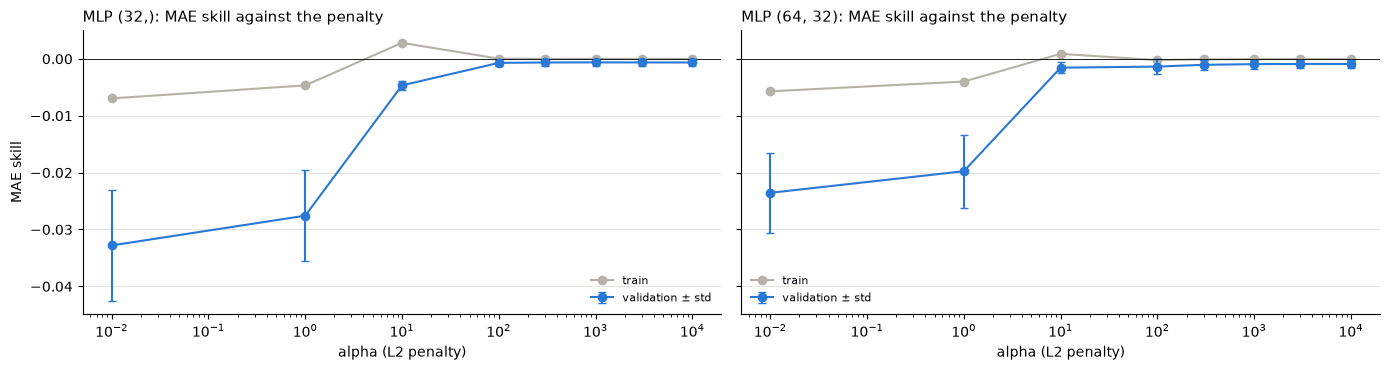

In [8]:
make_mlp = lambda **p: make_pipeline(StandardScaler(), MLPRegressor(max_iter=300, early_stopping=True, random_state=RANDOM_STATE, **p))
MLP_SIZES = [(32,), (64, 32)]
mlp_cv = val_tune(make_mlp, {"hidden_layer_sizes": MLP_SIZES, "alpha": [0.01, 1.0, 10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]})
p_mlp = best_params(mlp_cv, ["hidden_layer_sizes", "alpha"])
MLP_RET = f"MLP {p_mlp}"
final_report(MLP_RET, make_mlp(**p_mlp))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for a, size in zip(ax, MLP_SIZES):
    t = mlp_cv[mlp_cv["hidden_layer_sizes"].map(str) == str(size)].sort_values("alpha")
    a.plot(t["alpha"], t["train_skill"], "o-", color=GREY, label="train")
    a.errorbar(t["alpha"], t["val_skill"], yerr=t["val_skill_std"], fmt="o-", color=BLUE, capsize=3, label="validation ± std")
    a.axhline(0, color="k", lw=0.6)
    a.set_xscale("log")
    a.set_xlabel("alpha (L2 penalty)")
    a.legend(frameon=False, fontsize=8)
    tidy(a, f"MLP {size}: MAE skill against the penalty")
ax[0].set_ylabel("MAE skill")
plt.tight_layout()
plt.show()

### 3.2 RNN and LSTM on the 168-hour sequence

*(`model_test.ipynb`)* "A stacked `nn.RNN` or `nn.LSTM` reads the 168-hour sequence and a linear head maps the last hidden state to the 24 predictions. Trained with AdamW, gradient clipping and early stopping on validation MSE." Its settings are kept: hidden size 64, 2 layers, dropout 0.2, learning rate 10⁻³, weight decay 10⁻⁴, batches of 512, at most 30 epochs, patience 5, targets divided by their train standard deviation.

| | `model_test.ipynb` | here |
|---|---|---|
| inputs | the 168 × 6 windows of the old `.npz` (OHLCV + return), global scaler or raw | 168 × 9 window-normalized channels (section 1.4, README task 7) |
| data and validation | 2017 → Oct 2026, 80/20 split; validation = the last 10% of train | the common blocks; validation Jan 2023 → Jun 2024 |
| loss | MSE | MSE, and **Huber** (README task 10): quadratic for small errors and linear for large ones (δ = 1 train standard deviation of the target), so the few extreme hours weigh less |
| final model | the early-stopped network | refitted on train + validation for the chosen number of epochs, `N_SEEDS` seeds averaged |

RNN, MSE loss                                 MAE=0.3198  skill=-0.0017  R2oos=-0.0019  IC=+0.002  DayDir=0.484 (p=0.83)  DayBalAcc=0.483
RNN, Huber loss                               MAE=0.3196  skill=-0.0009  R2oos=-0.0015  IC=+0.004  DayDir=0.498 (p=0.56)  DayBalAcc=0.498
LSTM, MSE loss                                MAE=0.3196  skill=-0.0010  R2oos=-0.0010  IC=+0.006  DayDir=0.499 (p=0.53)  DayBalAcc=0.499
LSTM, Huber loss                              MAE=0.3194  skill=-0.0003  R2oos=-0.0004  IC=+0.003  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


,epochs,val MAE_skill,val R2_oos,val IC,"test R2_oos, single seeds",seconds
"RNN, MSE loss",4,-0.0035,-0.0029,0.0041,-0.0027 ± 0.0002,95
"RNN, Huber loss",8,-0.0009,-0.0011,0.0102,-0.0018 ± 0.0002,138
"LSTM, MSE loss",6,-0.0021,-0.0016,0.0018,-0.0014 ± 0.0003,101
"LSTM, Huber loss",3,-0.0002,-0.0003,-0.0009,-0.0005 ± 0.0001,60


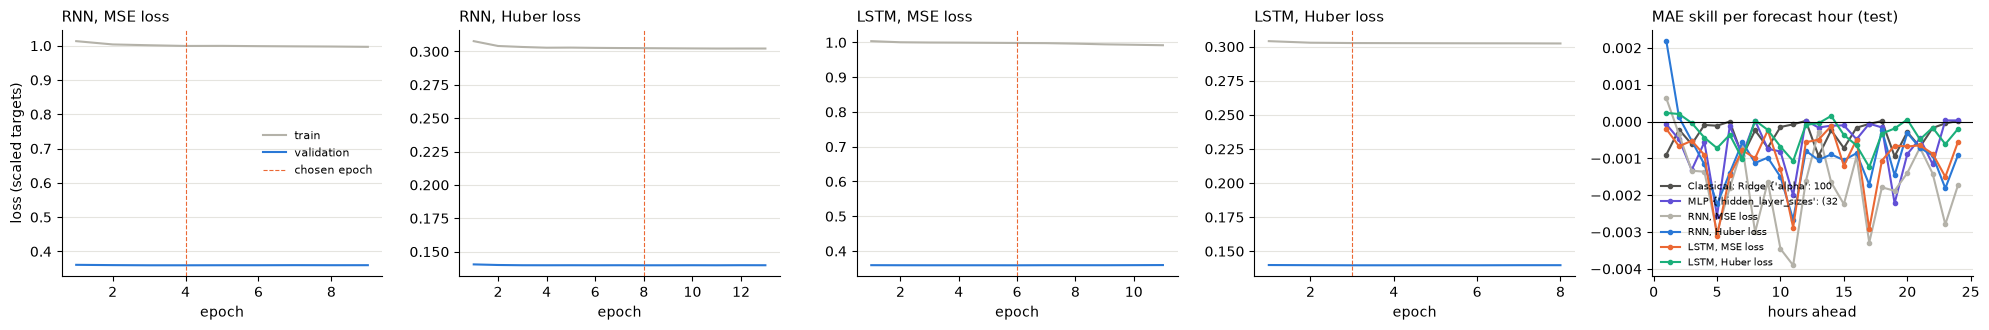

In [9]:
y_sd = Ytr.std()
RNN_KW = dict(hidden_size=64, num_layers=2, dropout=0.2)
TRAIN_KW = dict(epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
rnn_runs = {}
for cell in ("rnn", "lstm"):
    for loss in ("mse", "huber"):
        name = f"{cell.upper()}, {'MSE' if loss == 'mse' else 'Huber'} loss"
        make_net = lambda cell=cell: RecurrentNet(cell, len(CHANNELS), n_out=24, **RNN_KW)
        t0 = time.time()
        pv, ep, hist = early_stop_fit(make_net, S["train"], Ytr, S["val"], Yva, scale=y_sd, loss=loss, **TRAIN_KW)
        preds = refit_net(make_net, S["tv"], Ytv, S["test"], ep, scale=y_sd, loss=loss, **TRAIN_KW)
        final_report(name, pred=np.mean(preds, axis=0))
        rnn_runs[name] = {"epochs": ep, "hist": hist, **{f"val {k}": v for k, v in metrics(Yva, pv).items() if k in ("MAE_skill", "R2_oos", "IC")},
                          "test R2_oos, single seeds": seed_spread(Yte, preds, U.r2_oos), "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(rnn_runs, orient="index").drop(columns="hist").round(4))

fig, ax = plt.subplots(1, 5, figsize=(20, 3.4))
for a, (name, r) in zip(ax, rnn_runs.items()):
    a.plot(range(1, len(r["hist"]["train"]) + 1), r["hist"]["train"], color=GREY, label="train")
    a.plot(range(1, len(r["hist"]["val"]) + 1), r["hist"]["val"], color=BLUE, label="validation")
    a.axvline(r["epochs"], color=ORANGE, ls="--", lw=0.8, label="chosen epoch")
    a.set_xlabel("epoch")
    tidy(a, name)
ax[0].set_ylabel("loss (scaled targets)")
ax[0].legend(frameon=False, fontsize=8)
mae0_h = np.abs(Yte).mean(axis=0)
for (name, pred), c in zip([(k, v) for k, v in test_preds.items() if not k.startswith("Baseline")], [INK, PURPLE, GREY, BLUE, ORANGE, AQUA]):
    ax[4].plot(range(1, 25), 1 - np.abs(Yte - pred).mean(axis=0) / mae0_h, marker=".", color=c, label=name[:30])
ax[4].axhline(0, color="k", lw=0.8)
ax[4].set_xlabel("hours ahead")
ax[4].legend(frameon=False, fontsize=7)
tidy(ax[4], "MAE skill per forecast hour (test)")
plt.tight_layout()
plt.show()

### 3.3 Comparison on the test block

`DayDirAcc_indep`, `p_value` and `DayBalAcc_indep` come from the independent test days. The network **chosen without the test** is the one with the best validation MAE skill (the criterion of versions 1–2).

In [10]:
summary = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
cols = ["MAE", "RMSE", "MAE_skill", "R2_oos", "IC", "HourDirAcc", "DayDirAcc_indep", "p_value", "DayBalAcc_indep"]
display(summary[cols].sort_values("MAE").round(4))

ret_val_skill = {MLP_RET: mlp_cv.loc[0, "val_skill"], **{k: v["val MAE_skill"] for k, v in rnn_runs.items()}}
RET_CHOSEN = max(ret_val_skill, key=ret_val_skill.get)
nets = summary.loc[list(ret_val_skill)]
print(f"chosen on validation: {RET_CHOSEN} (validation MAE skill {ret_val_skill[RET_CHOSEN]:+.4f})")
SUMMARY.append({"question": "24 hourly returns", "network (chosen without the test)": f"{RET_CHOSEN} (of MLP, RNN / LSTM with MSE / Huber)",
                "test result": f"MAE skill {nets.loc[RET_CHOSEN, 'MAE_skill']:+.4f} (all networks {nets['MAE_skill'].min():+.4f} to "
                               f"{nets['MAE_skill'].max():+.4f}), IC {nets.loc[RET_CHOSEN, 'IC']:+.3f}",
                "classical reference (refitted here)": f"Ridge: MAE skill {summary.loc[f'Classical: Ridge {p_ridge}', 'MAE_skill']:+.4f}"})

,MAE,RMSE,MAE_skill,R2_oos,IC,HourDirAcc,DayDirAcc_indep,p_value,DayBalAcc_indep
Model,,,,,,,,,
Baseline: zero,0.3193,0.4925,-0.0000,0.0000,NaN,0.4960,0.4994,0.5277,0.5000
"LSTM, Huber loss",0.3194,0.4926,-0.0003,-0.0004,0.0028,0.5019,0.5006,0.5000,0.5000
Classical: Ridge {'alpha': 1000000.0},0.3194,0.4926,-0.0003,-0.0003,0.0003,0.5026,0.5006,0.5000,0.5000
Baseline: mean per hour,0.3194,0.4926,-0.0004,-0.0004,0.0000,0.5027,0.5006,0.5000,0.5000
"MLP {'hidden_layer_sizes': (32,), 'alpha': 1000.0}",0.3195,0.4926,-0.0006,-0.0006,-0.0000,0.5020,0.5006,0.5000,0.5000
"RNN, Huber loss",0.3196,0.4928,-0.0009,-0.0015,0.0035,0.5031,0.4982,0.5552,0.4976
"LSTM, MSE loss",0.3196,0.4927,-0.0010,-0.0010,0.0055,0.5023,0.4994,0.5277,0.4990
"RNN, MSE loss",0.3198,0.4929,-0.0017,-0.0019,0.0025,0.5021,0.4837,0.8346,0.4834


chosen on validation: LSTM, Huber loss (validation MAE skill -0.0002)


**What we see**

*(`bitcoin-models-new-data.ipynb`, version 1, conclusion 3)* "*MLP:* weak regularization (alpha 0.01–1) overfits badly (validation skill down to −0.04); alpha = 100 brings it back near 0. In every case, **the more a model is allowed to fit the training data, the worse it does on new periods.** That is the signature of a target that is mostly noise." On test the MLP (32,), alpha 100, had MAE skill −0.0008 and 53.4% daily direction accuracy (p = 0.01), with balanced accuracy 0.500: "the models effectively predict 'always up'".

*(`bitcoin-models-2018-2026.ipynb`, version 2, conclusion 3)* "*MLP:* weak penalties overfit (validation down to −0.037). From alpha = 1000 on the result does not change (plateau)." On test the MLP (32,), alpha 1000, had MAE skill −0.0004, IC −0.000 and 50.4% daily direction accuracy (p = 0.42).

*(`models-and-hyperparameters-ver1.ipynb`)* The early draft chose (64, 32) with alpha 1 on its grid 0.0001–1: test MAE 0.3289, daily direction 50.6%.

*(`model_test.ipynb`, README)* "Stacked RNNs and LSTMs in PyTorch read the 168-hour sequence directly, with both scaled and unscaled inputs. All four variants end up equal to the zero forecast (MSE ratio 1.000–1.002) with ~50% direction accuracy. The training loss barely moves from the first epoch." In its log the validation loss is 0.433 from the first epoch, and early stopping ends training after 8–21 epochs.

**This run:** *Pending.* To check: do the window-normalized inputs and the Huber loss move the recurrent networks away from the zero forecast?

## 4. The direction of the next hour

*Question and texts from `v3-extensions.ipynb`, section 5; classical results in `classical-models.ipynb`, section 5.*

The classical models found "a real but small effect for **one hour ahead only**", mostly the reversal of the last hour. The references are refitted here:

- **Reversal rule:** "'the next hour goes the opposite way of the last hour', no learning."
- **Gradient Boosting classifier** on the base features, with the grid of `classical-models.ipynb` tuned on validation by AUC. (The Binance attributes are left out: "With the Binance attributes the AUC is the same (0.537)", `v3-extensions.ipynb`.)

Networks:

- **MLP classifier** (scikit-learn `MLPClassifier`) on the 42 base features. Size, L2 penalty and number of epochs (`max_iter`, early stopping off) are tuned on validation by AUC.
- **LSTM classifier** on the 168-hour sequence, binary cross-entropy loss, early stopping on validation. The reversal lives in the last hours of the window; the LSTM sees them directly, together with their size, range and volume.
- **Every origin.** For this target consecutive origins do *not* share their target: each origin predicts a different hour. Keeping every 6th origin throws away 5/6 of the training examples, so Gradient Boosting and the LSTM are also trained on every origin.

"Metrics on every test hour (≈ 19,800): AUC, and the accuracy on the 10% most confident forecasts (binomial test against 50%)." *(`v3-extensions.ipynb`)*

,val AUC,AUC,accuracy top 10%,p-value,"test AUC, single seeds"
Reversal rule,0.5460,0.5278,0.5459,2.4e-05,
"Classical: GB classifier {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 200}",0.5596,0.5377,0.5524,1.6e-06,
"Classical: GB classifier, every origin {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 200}",0.5650,0.5383,0.5509,3.1e-06,
"MLP classifier {'alpha': 1.0, 'hidden_layer_sizes': (32,), 'max_iter': 30}",0.5518,0.5301,0.5544,6.8e-07,0.5286 ± 0.0023
LSTM classifier (7 epochs),0.5417,0.5319,0.5464,2.0e-05,0.5315 ± 0.0025
"LSTM classifier, every origin (9 epochs)",0.5715,0.5388,0.5948,1.5e-17,0.5385 ± 0.0015


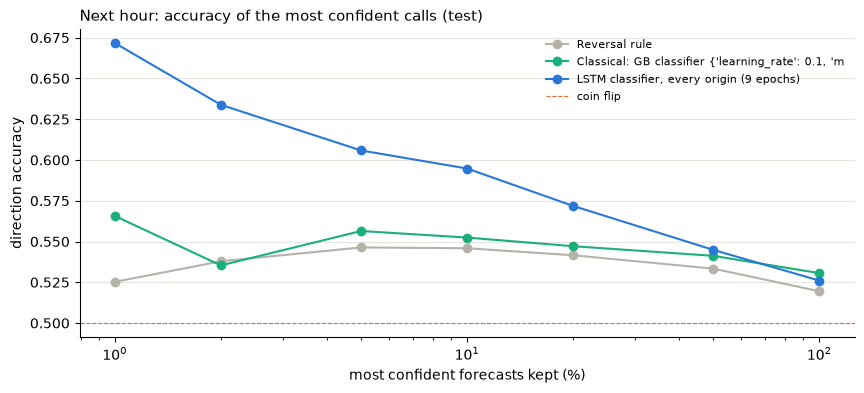

In [11]:
y1 = {k: Y[k][:, 0] for k in P}                                      # the next hour's return
up = {k: (v > 0).astype(np.float32) for k, v in y1.items()}


def direction_row(score, y):
    nz = y != 0
    score, y = score[nz], y[nz]
    centred = score - np.median(score)
    top = np.argsort(-np.abs(centred))[:len(score) // 10]
    hits = (centred[top] > 0) == (y[top] > 0)
    return {"AUC": roc_auc_score(y > 0, score), "accuracy top 10%": hits.mean(),
            "p-value": stats.binomtest(int(hits.sum()), len(top), 0.5, alternative="greater").pvalue}


def tune_by_auc(make, grid, Xa, ya, Xv, yv):
    # Fit each setting on (Xa, ya > 0), AUC on the validation block -> (best setting, its AUC)
    grid = list(ParameterGrid(grid))
    auc = [roc_auc_score(yv > 0, make(**p).fit(Xa, ya > 0).predict_proba(Xv)[:, 1]) for p in grid]
    return grid[int(np.argmax(auc))], max(auc)


dir_rows, dir_scores = {}, {}


def add_dir(name, val_auc, score, seed_scores=None):
    dir_scores[name] = score
    dir_rows[name] = {"val AUC": val_auc, **direction_row(score, y1["test"]),
                      "test AUC, single seeds": seed_spread(y1["test"] > 0, seed_scores, roc_auc_score) if seed_scores else ""}


add_dir("Reversal rule", roc_auc_score(y1["val"] > 0, -FEAT["ret_lag1"].values[P["val"]]), -FEAT["ret_lag1"].values[P["test"]])

make_clf = lambda **p: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
CLF_GRID = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [200, 1000]}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    p, auc = tune_by_auc(make_clf, CLF_GRID, Xw(tr, BASE), y1[tr], Fva, y1["val"])
    add_dir(f"Classical: GB classifier{tag} {p}", auc, make_clf(**p).fit(Xw(tv, BASE), y1[tv] > 0).predict_proba(Fte)[:, 1])
GB_DIR = [k for k in dir_rows if k.startswith("Classical: GB classifier {")][0]

make_mlpc = lambda seed=RANDOM_STATE, **p: make_pipeline(StandardScaler(), MLPClassifier(early_stopping=False, random_state=seed, **p))
p_mlpc, auc = tune_by_auc(make_mlpc, {"hidden_layer_sizes": [(32,), (64, 32)], "alpha": [0.1, 1.0, 10.0, 100.0], "max_iter": [10, 30, 100]},
                          Ftr, y1["train"], Fva, y1["val"])
probas = [make_mlpc(seed=RANDOM_STATE + s, **p_mlpc).fit(Ftv, y1["tv"] > 0).predict_proba(Fte)[:, 1] for s in range(N_SEEDS)]
add_dir(f"MLP classifier {p_mlpc}", auc, np.mean(probas, axis=0), probas)

S["train1"], S["tv1"] = seq("train1"), seq("tv1")                   # every origin (also used in section 5)
make_lstm_clf = lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=64, num_layers=2, dropout=0.2, n_out=1)
CLF_KW = dict(loss="bce", epochs=30, patience=5, lr=1e-3, weight_decay=1e-4, batch=512)
lstm_clf_hist = {}
for tag, tr, tv in [("", "train", "tv"), (", every origin", "train1", "tv1")]:
    pv, ep, lstm_clf_hist[tag] = early_stop_fit(make_lstm_clf, S[tr], up[tr], S["val"], up["val"], **CLF_KW)
    logits = refit_net(make_lstm_clf, S[tv], up[tv], S["test"], ep, **CLF_KW)
    add_dir(f"LSTM classifier{tag} ({ep} epochs)", roc_auc_score(up["val"], pv), np.mean(logits, axis=0), logits)

dir_tab = pd.DataFrame.from_dict(dir_rows, orient="index")
display(dir_tab.assign(**{"p-value": dir_tab["p-value"].map("{:.1e}".format)}).round(4))

SHARES = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]


def confidence_curve(score, y):
    # Direction accuracy on the q most confident forecasts (|score - median| largest), zero returns left out
    nz = y != 0
    c = score[nz] - np.median(score[nz])
    hits = ((c > 0) == (y[nz] > 0))[np.argsort(-np.abs(c))]
    return [hits[:max(1, int(len(hits) * q))].mean() for q in SHARES]


nets_dir = [k for k in dir_rows if not k.startswith(("Reversal", "Classical"))]
DIR_CHOSEN = max(nets_dir, key=lambda k: dir_rows[k]["val AUC"])
fig, ax = plt.subplots(figsize=(10, 4))
for k, c in zip(["Reversal rule", GB_DIR, DIR_CHOSEN], [GREY, AQUA, BLUE]):
    ax.plot([100 * q for q in SHARES], confidence_curve(dir_scores[k], y1["test"]), "o-", color=c, label=k[:50])
ax.axhline(0.5, color=ORANGE, ls="--", lw=0.8, label="coin flip")
ax.set_xscale("log")
ax.set_xlabel("most confident forecasts kept (%)")
ax.set_ylabel("direction accuracy")
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Next hour: accuracy of the most confident calls (test)")
plt.show()

SUMMARY.append({"question": "direction of the next hour", "network (chosen without the test)": f"{DIR_CHOSEN.split(' {')[0]} (best validation AUC)",
                "test result": f"AUC {dir_rows[DIR_CHOSEN]['AUC']:.3f}, top 10% right {dir_rows[DIR_CHOSEN]['accuracy top 10%']:.1%} "
                               f"(p = {dir_rows[DIR_CHOSEN]['p-value']:.0e})",
                "classical reference (refitted here)": f"GB AUC {dir_rows[GB_DIR]['AUC']:.3f}; reversal rule {dir_rows['Reversal rule']['AUC']:.3f}"})

**What we see**

*(`v3-extensions.ipynb`, section 5, quoted in `classical-models.ipynb`)* "**The reversal is stable.** [...] the simple rule still has AUC **0.528**, and its 10% most confident forecasts are right **54.6%** of the time (p = 3×10⁻⁵)." "**Gradient Boosting adds a little:** AUC **0.537** on base features." "This is a real but small effect for **one hour ahead only**: about 55 correct out of 100 confident calls, before any trading costs."

No archived notebook trained a network on this target.

**This run:** *Pending.* To check: does any network beat the Gradient Boosting classifier, and is a gain due to the network or to training on every origin (compare with "GB classifier, every origin")?

## 5. The size of each hourly move

*Target and texts from `bitcoin-models-v3.ipynb`, section 5 (A2 + A6), as in `classical-models.ipynb`, section 6.*

"The **size** of hourly moves is strongly autocorrelated while the direction is not. So, next to the return target, we predict **|r_h|: the absolute return of each of the 24 next hours**, in %." The models are trained with squared error and judged by R². This is the target where the classical models find the clearest hourly signal (last run: Gradient Boosting R² 0.117 fitted once, 0.144 refitted every month, against 0.053 for the best rule), and the one task 10 of the README asks the recurrent models to try.

| Network | Input | Output | Question |
|---|---|---|---|
| **MLP, long format** | the 47 columns of the long format (base + per-hour), standardized | one \|r\| per row | on the very same rows as Gradient Boosting: is a network better than trees? |
| **LSTM** | the 168 × 9 sequence (section 1.4) | the 24 \|r\| of the next day | can the network build its own features from the raw week? |
| **every origin** | the same | the same | do the networks gain from 6× more (overlapping) rows? Gradient Boosting is retrained the same way, to separate "more rows" from "a network" |
| **ensembles** | — | average of Gradient Boosting and the networks | "Ridge and the trees make *different* errors (linear vs. non-linear), and averaging cancels part of them" (version 3, C5) |

### 5.1 Baselines and the classical reference

Gradient Boosting on the long format, tuned on the grid of `classical-models.ipynb` (section 6.1) and fitted once on train + validation.

In [12]:
XA = {k: Xl(k, BASE) for k in ("train", "val", "test", "tv")}
ya = {k: yl(k) for k in ("train", "val", "test", "tv")}
abs_sd = ya["train"].std()


def abs_baselines(block):
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return {"Baseline: training mean": np.full(len(p), ya["train"].mean()),
            "Baseline: last week": week_abs[p],
            "Baseline: last week x hour profile": rule_abs(block)}


make_abs_gb = lambda **p: make_gb(min_samples_leaf=1000, **p)
print("Gradient Boosting (classical reference) on the validation block")
_, p_abs_gb = tune(make_abs_gb, {"learning_rate": [0.05, 0.1], "max_depth": [2, 3, 6]}, XA["train"], ya["train"], XA["val"], ya["val"], vol_scores)
GB_ABS = "Classical: Gradient Boosting"
abs_val = {**abs_baselines("val"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["train"], ya["train"]).predict(XA["val"])}
abs_test = {**abs_baselines("test"), GB_ABS: make_abs_gb(**p_abs_gb).fit(XA["tv"], ya["tv"]).predict(XA["test"])}
abs_seeds = {}

Gradient Boosting (classical reference) on the validation block


,learning_rate,max_depth,score,MAE,corr,seconds
0,0.10,2,0.0908,0.2227,0.3020,1.3
1,0.10,3,0.0901,0.2220,0.3015,1.4
2,0.05,3,0.0896,0.2236,0.3004,1.5
3,0.05,2,0.0890,0.2253,0.3003,1.3
4,0.05,6,0.0866,0.2232,0.2963,2.0
5,0.10,6,0.0833,0.2233,0.2932,1.9


### 5.2 MLP in long format

A small grid of size and weight decay, dropout 0.1, AdamW with learning rate 10⁻³, batches of 2,048 rows, at most 40 epochs with patience 5. The inputs are standardized with the train block's mean and standard deviation.

In [13]:
sc_abs = StandardScaler().fit(XA["train"])
XA_s = {k: sc_abs.transform(v).astype(np.float32) for k, v in XA.items()}
ABS_MLP_KW = dict(epochs=40, patience=5, lr=1e-3, batch=2048)


def mlp_abs_spec(hidden, weight_decay):
    return (lambda: MLPNet(XA_s["train"].shape[1], hidden, n_out=1, dropout=0.1)), {"weight_decay": weight_decay}


_, mlp_abs_best = nn_grid(mlp_abs_spec, {"hidden": [(64, 32), (256, 128)], "weight_decay": [1e-4, 1e-2]},
                          XA_s["train"], ya["train"], XA_s["val"], ya["val"], vol_scores, scale=abs_sd, **ABS_MLP_KW)
MLP_ABS = f"MLP, long format {mlp_abs_best['params']}"
abs_val[MLP_ABS] = mlp_abs_best["val"]
abs_seeds[MLP_ABS] = refit_best(mlp_abs_spec, mlp_abs_best, XA_s["tv"], ya["tv"], XA_s["test"], abs_sd, **ABS_MLP_KW)

,hidden,weight_decay,score,MAE,corr,epochs,seconds
0,"(64, 32)",0.0001,0.0917,0.2215,0.3032,10,6.6
1,"(64, 32)",0.0100,0.0915,0.2217,0.3029,10,6.4
3,"(256, 128)",0.0100,0.0871,0.2174,0.2968,2,9.5
2,"(256, 128)",0.0001,0.0870,0.2178,0.2964,2,9.5


### 5.3 LSTM on the 168-hour sequence

The architecture of `model_test.ipynb` (2 layers, dropout 0.2) with a small grid of hidden sizes; at most 60 epochs with patience 8. One network predicts the 24 values of the next day, so its output, flattened origin by origin, lines up with the rows of the long format.

In [14]:
LSTM_KW = dict(epochs=60, patience=8, lr=1e-3, weight_decay=1e-4, batch=512)
r2_flat = lambda y, p: vol_scores(np.ravel(y), np.ravel(p))


def lstm_abs_spec(hidden_size):
    return (lambda: RecurrentNet("lstm", len(CHANNELS), hidden_size=hidden_size, num_layers=2, dropout=0.2, n_out=24)), {}


_, lstm_abs_best = nn_grid(lstm_abs_spec, {"hidden_size": [32, 64, 128]}, S["train"], np.abs(Y["train"]), S["val"], np.abs(Y["val"]),
                           r2_flat, scale=abs_sd, **LSTM_KW)
LSTM_ABS = f"LSTM {lstm_abs_best['params']}"
abs_val[LSTM_ABS] = lstm_abs_best["val"].reshape(-1)
abs_seeds[LSTM_ABS] = [q.reshape(-1) for q in refit_best(lstm_abs_spec, lstm_abs_best, S["tv"], np.abs(Y["tv"]), S["test"], abs_sd, **LSTM_KW)]

,hidden_size,score,MAE,corr,epochs,seconds
2,128,0.0963,0.2199,0.3105,21,307.1
0,32,0.0952,0.2244,0.3110,58,111.7
1,64,0.0937,0.2233,0.3072,30,150.5


### 5.4 Every origin

The settings chosen above, trained on every origin of the train block (early stopping on the same validation block) and refitted on every origin of train + validation. Gradient Boosting is retrained the same way.

In [15]:
XA1 = {k: Xl(k, BASE) for k in ("train1", "tv1")}
ya1 = {k: yl(k) for k in ("train1", "tv1")}
GB_ABS1 = f"{GB_ABS}, every origin"
abs_val[GB_ABS1] = make_abs_gb(**p_abs_gb).fit(XA1["train1"], ya1["train1"]).predict(XA["val"])
abs_test[GB_ABS1] = make_abs_gb(**p_abs_gb).fit(XA1["tv1"], ya1["tv1"]).predict(XA["test"])
XA1 = {k: sc_abs.transform(v).astype(np.float32) for k, v in XA1.items()}

every_origin = {}
for name, spec, best, X1, y1_, Xv, yv, Xte, kw in [
        (f"{MLP_ABS}, every origin", mlp_abs_spec, mlp_abs_best, XA1, ya1, XA_s["val"], ya["val"], XA_s["test"], ABS_MLP_KW),
        (f"{LSTM_ABS}, every origin", lstm_abs_spec, lstm_abs_best, {k: S[k] for k in ("train1", "tv1")},
         {k: np.abs(Y[k]) for k in ("train1", "tv1")}, S["val"], np.abs(Y["val"]), S["test"], LSTM_KW)]:
    t0 = time.time()
    make_net, tkw = spec(**best["params"])
    pv, ep, _ = early_stop_fit(make_net, X1["train1"], y1_["train1"], Xv, yv, abs_sd, **{**kw, **tkw})
    abs_val[name] = pv.reshape(-1)
    abs_seeds[name] = [q.reshape(-1) for q in refit_net(make_net, X1["tv1"], y1_["tv1"], Xte, ep, abs_sd, **{**kw, **tkw})]
    every_origin[name] = {"epochs": ep, "val R2": U.r2(ya["val"], abs_val[name]), "seconds": round(time.time() - t0)}
display(pd.DataFrame.from_dict(every_origin, orient="index").round(4))
del XA1, ya1

,epochs,val R2,seconds
"MLP, long format {'hidden': (64, 32), 'weight_decay': 0.0001}, every origin",3,0.0959,55
"LSTM {'hidden_size': 128}, every origin",15,0.1053,4653


### 5.5 Test block

Every model fitted once on train + validation and evaluated once on the test block (every origin × 24 hours). The ensembles average Gradient Boosting with the networks, without weights (no extra hyperparameter to overfit). The validation R² is the one to choose by: for the networks it comes from the early-stopped fit on the train block (one seed), for the ensembles from the average of those validation forecasts.

,val R2,test R2,test MAE,test corr,"test R2, single seeds"
Baseline: training mean,-0.2217,-0.1953,0.3248,NaN,
Baseline: last week,0.0355,0.0377,0.2369,0.2087,
Baseline: last week x hour profile,0.0481,0.0529,0.2349,0.2386,
Classical: Gradient Boosting,0.0908,0.1167,0.2225,0.3420,
"Classical: Gradient Boosting, every origin",0.0931,0.1176,0.2225,0.3434,
"MLP, long format {'hidden': (64, 32), 'weight_decay': 0.0001}",0.0917,0.1167,0.2202,0.3439,0.1136 ± 0.0013
LSTM {'hidden_size': 128},0.0963,0.1044,0.2216,0.3256,0.1018 ± 0.0017
"MLP, long format {'hidden': (64, 32), 'weight_decay': 0.0001}, every origin",0.0959,0.1209,0.2189,0.3514,0.1188 ± 0.0025
"LSTM {'hidden_size': 128}, every origin",0.1053,0.1179,0.2208,0.3441,0.1052 ± 0.0043
Ensemble: GB + MLP,0.0962,0.1208,0.2206,0.3492,


chosen on validation (networks and ensembles): Ensemble, every origin: GB + MLP + LSTM


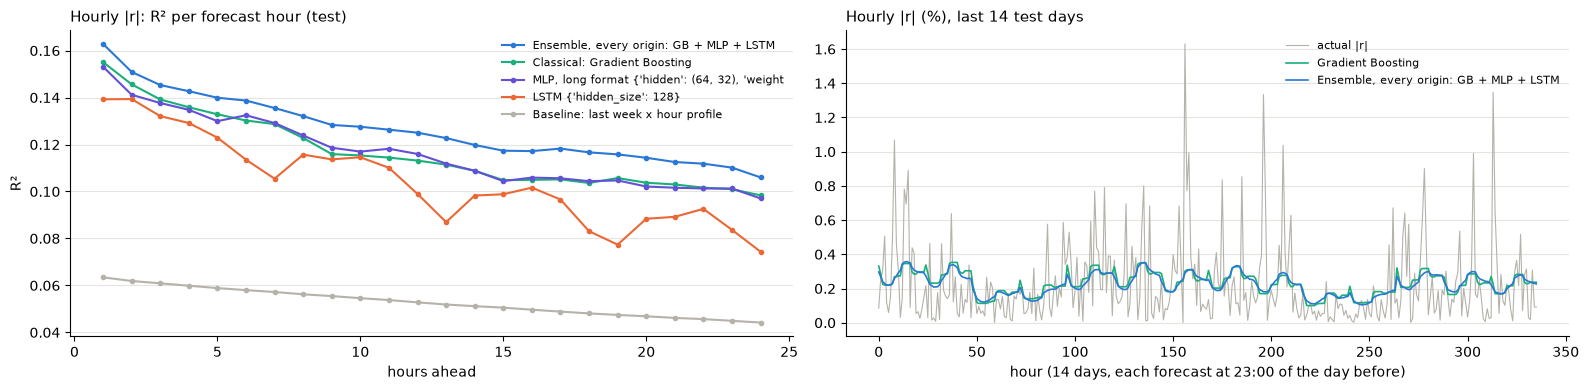

In [16]:
for k, v in abs_seeds.items():
    abs_test[k] = np.mean(v, axis=0)
ENS_ABS = {"Ensemble: GB + MLP": [GB_ABS, MLP_ABS], "Ensemble: GB + LSTM": [GB_ABS, LSTM_ABS],
           "Ensemble: GB + MLP + LSTM": [GB_ABS, MLP_ABS, LSTM_ABS],
           "Ensemble, every origin: GB + MLP + LSTM": [GB_ABS1, f"{MLP_ABS}, every origin", f"{LSTM_ABS}, every origin"]}
for e, members in ENS_ABS.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)

abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"]),
                                       "test R2, single seeds": seed_spread(ya["test"], abs_seeds[k], U.r2) if k in abs_seeds else ""}
                                   for k, v in abs_test.items()}, orient="index")
display(abs_tab.round(4))
ABS_CHOSEN = abs_tab.drop([k for k in abs_tab.index if k.startswith(("Baseline", "Classical"))])["val R2"].idxmax()
print(f"chosen on validation (networks and ensembles): {ABS_CHOSEN}")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
for k, c in [(ABS_CHOSEN, BLUE), (GB_ABS, AQUA), (MLP_ABS, PURPLE), (LSTM_ABS, ORANGE), ("Baseline: last week x hour profile", GREY)]:
    pr = abs_test[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:45])
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Yte[seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test[GB_ABS].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=AQUA, label="Gradient Boosting")
ax[1].plot(abs_test[ABS_CHOSEN].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=BLUE, label=ABS_CHOSEN[:45])
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "network (chosen without the test)": f"{ABS_CHOSEN} (best validation R2)",
                "test result": f"R2 {abs_tab.loc[ABS_CHOSEN, 'test R2']:.3f} (MLP {abs_tab.loc[MLP_ABS, 'test R2']:.3f}, "
                               f"LSTM {abs_tab.loc[LSTM_ABS, 'test R2']:.3f})",
                "classical reference (refitted here)": f"GB fitted once: R2 {abs_tab.loc[GB_ABS, 'test R2']:.3f}; "
                                                       f"rule {abs_tab.loc['Baseline: last week x hour profile', 'test R2']:.3f}"})

**What we see**

No archived notebook trained a network on this target. The classical reference *(`bitcoin-models-v3.ipynb`, section 5, quoted in `classical-models.ipynb`)*: "Gradient Boosting explains **11.7% of the hour-to-hour variation in the size of the move** [...], about **2.2× the best simple rule** (5.3%)." "The forecast follows the calm and agitated periods and the intraday rhythm, but not the individual spikes. Single extreme hours are news-driven and not predictable, which is why R² stays far below 1." Refitting Gradient Boosting every month raised it to 0.144 in the last run of `classical-models.ipynb` (section 6.5); the networks here are fitted once, so they compare with 0.117.

**This run:** *Pending.* To check: MLP vs. Gradient Boosting on the same rows; the LSTM on the raw week vs. the hand-made features; the effect of every origin, for the networks and for Gradient Boosting; whether an ensemble of two model families helps more than the tree ensembles did; the seed spread against the differences between models (and the intervals in section 8).

## 6. Next-day volatility

*Target and texts from `bitcoin-models-new-data.ipynb` (version 1, target C) and `bitcoin-models-v3.ipynb` (sections 9 and 11), as in `classical-models.ipynb`, section 8.4.*

Target: "the log of the next day's realized volatility, `ln √Σ(ln(1 + r_h))²` (in %)", forecast at 23:00 for the next calendar day, from the 42 base features (wide format). "**Volatility is predictable** (calm days follow calm days, wild days follow wild days, the so-called *volatility clustering*)." Models are chosen on the **4 walk-forward folds** over train + validation (C1); the test uses the independent days.

- **Classical reference:** Gradient Boosting with the grid of `classical-models.ipynb` (section 8.4); last run: walk-forward R² 0.459, test R² 0.477.
- **MLP** (scikit-learn `MLPRegressor`, standardized inputs): size, L2 penalty and number of epochs. As for Gradient Boosting (C2), early stopping is off and the number of epochs (`max_iter`) is tuned on the walk-forward folds.
- **Ensemble MLP + Gradient Boosting** (C5). In `classical-models.ipynb` "the three tree models make very similar errors, so averaging them changes little"; a network is a different model family.

MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty


param_mlpregressor__max_iter,25,50,100,200
mean_test_score,-0.3307,0.1581,0.3813,0.4524
std_test_score,0.5503,0.2227,0.0798,0.0371


,test R2,test MAE,test corr,"test R2, single seeds",WF R2,WF std,fold1,fold2,fold3,fold4
Baseline: last week's average volatility,0.0941,0.3851,0.4467,,NaN,NaN,NaN,NaN,NaN,NaN
"Classical: Gradient Boosting {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 100}",0.4765,0.2980,0.6926,,0.4587,0.0406,0.4573,0.5159,0.4382,0.4234
"MLP {'alpha': 1.0, 'hidden_layer_sizes': (16,), 'max_iter': 200}",0.4600,0.3034,0.6792,0.4564 ± 0.0072,0.4524,0.0429,0.4502,0.5118,0.4365,0.4108
Ensemble: GB + MLP,0.4772,0.2981,0.6932,,0.4721,0.0454,0.4835,0.5302,0.4488,0.4259


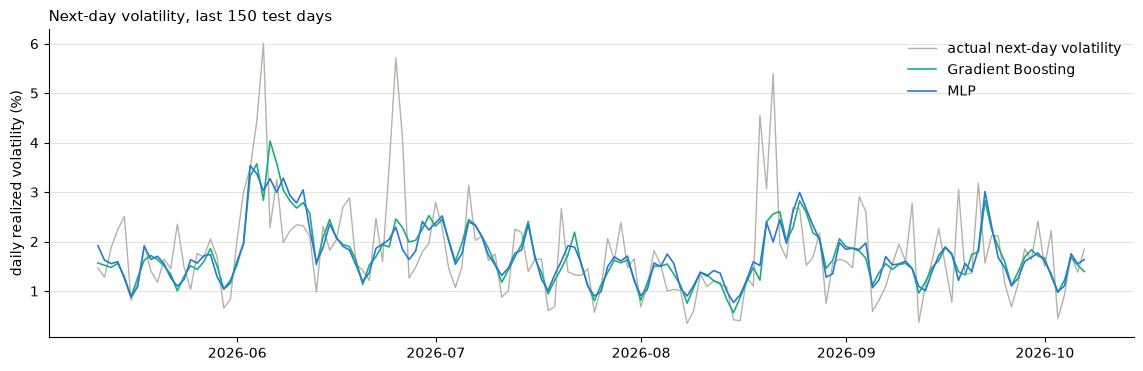

In [17]:
XW_tv, XW_te = Ftv, Fte[test_days]
yd_tv, yd_te = U.day_log_vol(Ytv), U.day_log_vol(Yte[test_days])
lr_h = np.log1p(ret / U.PCT) * U.PCT                                 # hourly log returns, %
p_days = P["test"][test_days]
NAIVE_DV = "Baseline: last week's average volatility"
dv_test = {NAIVE_DV: np.log(np.sqrt(np.array([(lr_h[p - 167: p + 1] ** 2).sum() / 7 for p in p_days])) + 1e-6)}


def wf_folds(gs):
    # walk-forward scores of the chosen setting: mean, std and each fold
    f = [gs.cv_results_[f"split{i}_test_score"][gs.best_index_] for i in range(len(WF))]
    return {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}


gb_dv = GridSearchCV(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
                     {"learning_rate": [0.05, 0.1], "max_depth": [2, 3], "min_samples_leaf": [20, 100], "max_iter": [50, 100, 200]},
                     cv=WF, scoring="r2", n_jobs=-1).fit(XW_tv, yd_tv)
MLP_DV_GRID = {"mlpregressor__hidden_layer_sizes": [(16,), (64, 32)], "mlpregressor__alpha": [0.1, 1.0, 10.0, 100.0],
               "mlpregressor__max_iter": [25, 50, 100, 200]}
mlp_dv = GridSearchCV(make_pipeline(StandardScaler(), MLPRegressor(early_stopping=False, random_state=RANDOM_STATE)),
                      MLP_DV_GRID, cv=WF, scoring="r2", n_jobs=-1).fit(XW_tv, yd_tv)
GB_DV = f"Classical: Gradient Boosting {gb_dv.best_params_}"
MLP_DV = f"MLP {({k.split('__')[1]: v for k, v in mlp_dv.best_params_.items()})}"
print("MLP: walk-forward R2 against the number of epochs, for the chosen size and penalty")
cv = pd.DataFrame(mlp_dv.cv_results_)
same = np.all([cv[f"param_{k}"].map(str) == str(v) for k, v in mlp_dv.best_params_.items() if not k.endswith("max_iter")], axis=0)
display(cv[same].set_index("param_mlpregressor__max_iter")[["mean_test_score", "std_test_score"]].T.round(4))

dv_wf = {GB_DV: wf_folds(gb_dv), MLP_DV: wf_folds(mlp_dv)}
fold_pred = {k: [clone(gs.best_estimator_).fit(XW_tv[a], yd_tv[a]).predict(XW_tv[b]) for a, b in WF] for k, gs in [(GB_DV, gb_dv), (MLP_DV, mlp_dv)]}
ENS_DV = "Ensemble: GB + MLP"
f = [U.r2(yd_tv[b], (fold_pred[GB_DV][i] + fold_pred[MLP_DV][i]) / 2) for i, (_, b) in enumerate(WF)]
dv_wf[ENS_DV] = {"WF R2": np.mean(f), "WF std": np.std(f, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(f)}}

dv_seeds = {MLP_DV: [clone(mlp_dv.best_estimator_).set_params(mlpregressor__random_state=RANDOM_STATE + s).fit(XW_tv, yd_tv).predict(XW_te)
                     for s in range(N_SEEDS)]}
dv_test.update({GB_DV: gb_dv.predict(XW_te), MLP_DV: np.mean(dv_seeds[MLP_DV], axis=0)})
dv_test[ENS_DV] = (dv_test[GB_DV] + dv_test[MLP_DV]) / 2
dv_tab = pd.DataFrame.from_dict({k: {**dv_wf.get(k, {}), "test R2": U.r2(yd_te, v), "test MAE": mean_absolute_error(yd_te, v),
                                      "test corr": safe_corr(v, yd_te),
                                      "test R2, single seeds": seed_spread(yd_te, dv_seeds[k], U.r2) if k in dv_seeds else ""}
                                  for k, v in dv_test.items()}, orient="index")
display(dv_tab.round(4))
DV_CHOSEN = max([MLP_DV, ENS_DV], key=lambda k: dv_wf[k]["WF R2"])

fig, ax = plt.subplots(figsize=(14, 4))
last = slice(-150, None)
ax.plot(D["test"][test_days][last], np.exp(yd_te[last]), color=GREY, lw=1, label="actual next-day volatility")
ax.plot(D["test"][test_days][last], np.exp(dv_test[GB_DV][last]), color=AQUA, lw=1.2, label="Gradient Boosting")
ax.plot(D["test"][test_days][last], np.exp(dv_test[MLP_DV][last]), color=BLUE, lw=1.2, label="MLP")
ax.set_ylabel("daily realized volatility (%)")
ax.legend(frameon=False)
tidy(ax, "Next-day volatility, last 150 test days")
plt.show()

SUMMARY.append({"question": "next-day volatility", "network (chosen without the test)": f"{DV_CHOSEN} (best walk-forward R2 of MLP / ensemble)",
                "test result": f"R2 {U.r2(yd_te, dv_test[DV_CHOSEN]):.3f} (MLP alone {U.r2(yd_te, dv_test[MLP_DV]):.3f})",
                "classical reference (refitted here)": f"GB: R2 {U.r2(yd_te, dv_test[GB_DV]):.3f}; last week's average {U.r2(yd_te, dv_test[NAIVE_DV]):.3f}"})

**What we see**

No archived notebook trained a network on this target. The classical reference *(`bitcoin-models-v3.ipynb`, section 11, quoted in `classical-models.ipynb`)*: "The non-linear tree models are clearly best for next-day volatility [...]. SVR is a little lower (0.434) but the **most stable** across folds." "For next-day volatility the ensembles do **not** beat the best single model on the walk-forward folds [...]. The three tree models make very similar errors, so averaging them changes little." "The fold-to-fold spread is large: the volatility R² changes by ±0.035–0.043 between periods. Any difference smaller than that, on a single block, cannot be trusted."

**This run:** *Pending.* To check: MLP vs. Gradient Boosting against the fold-to-fold spread; the number of epochs (does the walk-forward R² fall after a point, as for the number of trees?); whether the ensemble of two model families helps.

## 7. The course-lab MLP

*Section, code and texts from `course-methods.ipynb` (Filip), section 6, on the course-lab pipeline of `classical-models.ipynb`, section 9.*

"Finally a small Keras MLP for the move size: two hidden ReLU layers and one linear output neuron, trained with MSE. The last 20 % of the training days (in time order) are the validation set, and **early stopping** (Lab VI, Part XI) stops training when the validation loss stops improving."

The target is `size_next`, the average |hourly change| of the next 24 hours, forecast once a day at 23:00 from the 9 course attributes (`ret_1d`, `ret_7d`, `size_1d`, `vol_1d`, `vol_7d`, `range_1d`, `volume_ratio`, `last_hour`, `weekday`) through the course preprocessing pipeline. The fit days are the days of train + validation and the test days are those of the test block, as in `classical-models.ipynb` (section 9). The classical reference is Linear Regression, the best model of that section (last run: test R² 0.490).

The Keras code is the original of `course-methods.ipynb`, with its variable names mapped to those of this notebook (`train` → `fit_days`, `X_train` → `X_fit`, `X_test` → `X_test_c`, `y_train_size` → `y_fit_size`). As there, the network trained on the first 80% of the fit days and early-stopped on the last 20% is used directly on the test days, with one seed (42). It is not refitted on all fit days and not averaged over seeds, unlike the other networks of this notebook.

In [18]:
r_h, close, volume = hourly["Return"], hourly["Close"], hourly["Volume"].clip(lower=0)
attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "size_1d": r_h.abs().rolling(24).mean(),
    "vol_1d": r_h.rolling(24).std(),
    "vol_7d": r_h.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r_h,
    "weekday": (hourly.index + pd.Timedelta(hours=1)).day_name(),
})
attributes["size_next"] = r_h.abs().rolling(24).mean().shift(-24)    # average |hourly change| of the next 24 h

days = attributes[attributes.index.hour == 23].dropna()               # one forecast per day, at 23:00
fit_days = days[days.index + pd.Timedelta(hours=24) < TEST_START]     # train + validation: the next 24 h end before the test
test_c = days[days.index >= TEST_START - pd.Timedelta(hours=1)]
assert len(test_c) == ND and (test_c.index == D["test"][test_days]).all()   # the independent test days of section 1.2
num_cols = ["ret_1d", "ret_7d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]
cat_cols = ["weekday"]
X_fit, X_test_c = fit_days[num_cols + cat_cols], test_c[num_cols + cat_cols]
y_fit_size, y_test_size = fit_days["size_next"], test_c["size_next"]
print(f"fit:  {len(fit_days)} days {fit_days.index[0].date()} -> {fit_days.index[-1].date()}")
print(f"test: {len(test_c)} days {test_c.index[0].date()} -> {test_c.index[-1].date()}")

preprocessing = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


def make_pipe(model):
    # A fresh copy of the preprocessing followed by the model, so models never share fitted steps
    return Pipeline([("prep", clone(preprocessing)), ("model", model)])


size_preds = {"Same as today (baseline)": X_test_c["size_1d"].values,
              "Classical: Linear Regression": make_pipe(LinearRegression()).fit(X_fit, y_fit_size).predict(X_test_c)}

fit:  2365 days 2018-01-08 -> 2024-06-29
test: 829 days 2024-06-30 -> 2026-10-06


In [19]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow import keras

keras.utils.set_random_seed(42)

n_valid = int(len(fit_days) * 0.2)
nn_prep = clone(preprocessing)
X_tr_nn = nn_prep.fit_transform(X_fit.iloc[:-n_valid])
X_va_nn = nn_prep.transform(X_fit.iloc[-n_valid:])
X_te_nn = nn_prep.transform(X_test_c)
y_tr_nn, y_va_nn = y_fit_size.iloc[:-n_valid], y_fit_size.iloc[-n_valid:]

mlp = keras.models.Sequential([
    keras.layers.Input(shape=X_tr_nn.shape[1:]),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1),
])
mlp.compile(loss="mse", optimizer=keras.optimizers.SGD(learning_rate=0.01))

early_stopping = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
history = mlp.fit(X_tr_nn, y_tr_nn, epochs=500, validation_data=(X_va_nn, y_va_nn),
                  callbacks=[early_stopping], verbose=0)

mlp_pred = mlp.predict(X_te_nn, verbose=0).ravel()
print("Epochs run:", len(history.history["loss"]), "| best epoch:", int(np.argmin(history.history["val_loss"])) + 1)
print("MLP test RMSE:", round(np.sqrt(mean_squared_error(y_test_size, mlp_pred)), 4),
      "| R2:", round(r2_score(y_test_size, mlp_pred), 4))

Epochs run: 307 | best epoch: 287
MLP test RMSE: 0.1261 | R2: 0.3956


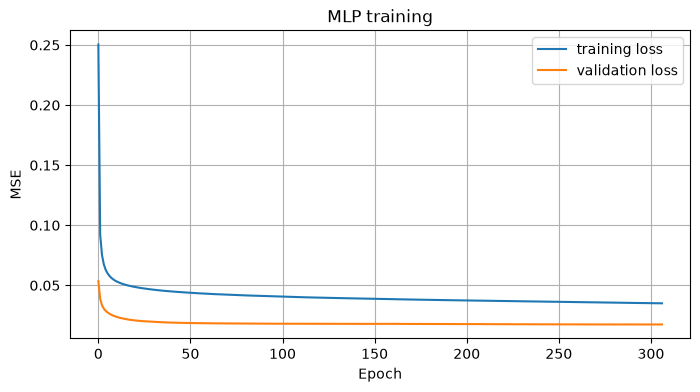

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MLP training")
plt.legend()
plt.grid(True)
plt.show()

All models on the test days, next to the classical reference:

,RMSE,MAE,R2
Same as today (baseline),0.1624,0.1190,-0.0019
Classical: Linear Regression,0.1159,0.0834,0.4900
MLP (Keras),0.1261,0.0945,0.3956


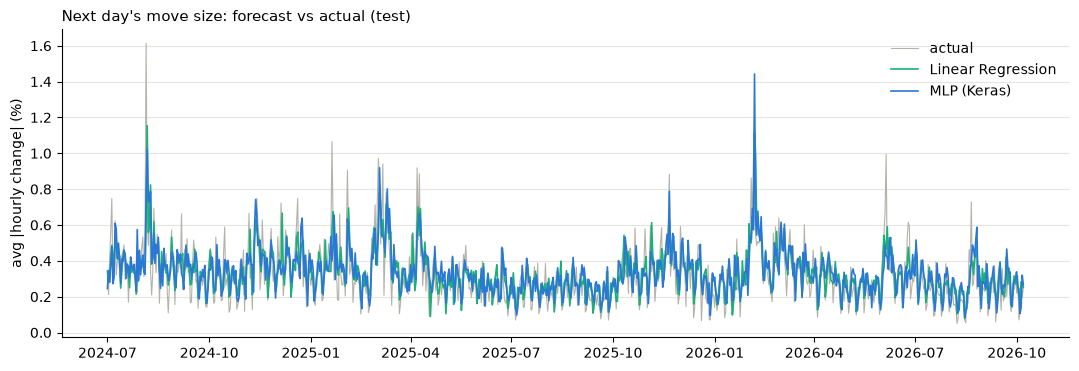

In [21]:
MLP_KERAS = "MLP (Keras)"
size_preds[MLP_KERAS] = mlp_pred
size_tab = pd.DataFrame({k: {"RMSE": np.sqrt(mean_squared_error(y_test_size, v)), "MAE": mean_absolute_error(y_test_size, v),
                             "R2": r2_score(y_test_size, v)} for k, v in size_preds.items()}).T
display(size_tab.round(4))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_c.index, y_test_size, lw=0.8, color=GREY, label="actual")
ax.plot(test_c.index, size_preds["Classical: Linear Regression"], lw=1.2, color=AQUA, label="Linear Regression")
ax.plot(test_c.index, mlp_pred, lw=1.2, color=BLUE, label="MLP (Keras)")
ax.set_ylabel("avg |hourly change| (%)")
ax.legend(frameon=False)
tidy(ax, "Next day's move size: forecast vs actual (test)")
plt.show()

SUMMARY.append({"question": "next-day move size (course pipeline)", "network (chosen without the test)": "Keras MLP (32, 16) of course-methods",
                "test result": f"R2 {size_tab.loc[MLP_KERAS, 'R2']:.3f}",
                "classical reference (refitted here)": f"Linear Regression: R2 {size_tab.loc['Classical: Linear Regression', 'R2']:.3f}"})

**What we see** *(`course-methods.ipynb`, section 6, train 2018–2023, test 2024 → Oct 2026)*

- "**Training:** Early stopping ended after 148 epochs and restored the weights from epoch 128, where the validation loss was lowest. The validation loss is lower than the training loss the whole time. This is not a mistake: the validation days (Oct 2022 – Dec 2023) were much calmer than the earlier training days (average move size 0.27 % vs 0.50 %), so their errors are smaller."
- "**Test set:** RMSE 0.133, **R² = 0.37**. That is clearly useful (much better than the baselines), but **worse than the simple Linear Regression** (0.48)."
- "**Why:** with about 1,750 training days and a relationship that is nearly linear, the network has nothing extra to learn and more parameters that can fit noise. Neural networks pay off with large amounts of data and complex patterns (images in Lab VI), not with a small table of 15 columns."

**This run:** *Pending.* To check: the MLP against Linear Regression on the common blocks (the archived run used train 2018–2023, test 2024 → Oct 2026).

## 8. How sure are we? Bootstrap confidence intervals

*Method from `bitcoin-models-v3.ipynb`, section 14 (D1), as in `classical-models.ipynb`, section 11.*

"The **moving-block bootstrap** estimates how much [a test number] could change with a different sample of days: the [...] test days are resampled in blocks of 10 consecutive days (blocks keep the volatility clustering intact) 1,000 times, and the statistic is recomputed each time. [...] For a **difference** between two models (computed on the same resampled days), an interval that excludes 0 means the difference is reliable."

For the hourly targets a resampled day brings all 24 test origins of that day. Every network or ensemble below is the one chosen without the test, compared with the classical reference refitted in this notebook.

In [22]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
r2_days = lambda pred, i: U.r2(ya["test"][days_rows(i)], pred[days_rows(i)])
auc_days = lambda score, i: roc_auc_score(y1["test"][day_orig(i)] > 0, score[day_orig(i)])
ret_chosen = test_preds[RET_CHOSEN]
boot_stats = {
    f"24 hourly returns R²_oos, {RET_CHOSEN}": lambda i: U.r2_oos(Yte[day_orig(i)], ret_chosen[day_orig(i)]),
    f"24 hourly returns IC, {RET_CHOSEN}": lambda i: safe_corr(ret_chosen[day_orig(i)], Yte[day_orig(i)]),
    f"next-hour AUC, {DIR_CHOSEN.split(' {')[0]} − GB": lambda i: auc_days(dir_scores[DIR_CHOSEN], i) - auc_days(dir_scores[GB_DIR], i),
    f"hourly |r| R², {ABS_CHOSEN}": lambda i: r2_days(abs_test[ABS_CHOSEN], i),
    f"hourly |r| R², {ABS_CHOSEN} − GB": lambda i: r2_days(abs_test[ABS_CHOSEN], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², MLP − GB": lambda i: r2_days(abs_test[MLP_ABS], i) - r2_days(abs_test[GB_ABS], i),
    "hourly |r| R², LSTM − GB": lambda i: r2_days(abs_test[LSTM_ABS], i) - r2_days(abs_test[GB_ABS], i),
    "next-day vol R², MLP − GB": lambda i: U.r2(yd_te[i], dv_test[MLP_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
    "next-day vol R², ensemble GB + MLP − GB": lambda i: U.r2(yd_te[i], dv_test[ENS_DV][i]) - U.r2(yd_te[i], dv_test[GB_DV][i]),
    "next-day move size R², MLP (Keras) − Linear Regression": lambda i: r2_score(y_test_size.values[i], mlp_pred[i])
                                                                       - r2_score(y_test_size.values[i], size_preds["Classical: Linear Regression"][i]),
}
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"24 hourly returns R²_oos, LSTM, Huber loss",-0.0004,-0.0009,0.0001,0.050
"24 hourly returns IC, LSTM, Huber loss",0.0028,-0.0021,0.0070,0.880
"next-hour AUC, LSTM classifier, every origin (9 epochs) − GB",0.0011,-0.0050,0.0074,0.695
"hourly |r| R², Ensemble, every origin: GB + MLP + LSTM",0.1266,0.1054,0.1507,1.000
"hourly |r| R², Ensemble, every origin: GB + MLP + LSTM − GB",0.0099,0.0073,0.0129,1.000
"hourly |r| R², MLP − GB",-0.0000,-0.0041,0.0038,0.544
"hourly |r| R², LSTM − GB",-0.0123,-0.0172,-0.0082,0.000
"next-day vol R², MLP − GB",-0.0165,-0.0359,-0.0001,0.025
"next-day vol R², ensemble GB + MLP − GB",0.0006,-0.0088,0.0088,0.546
"next-day move size R², MLP (Keras) − Linear Regression",-0.0943,-0.1742,-0.0310,0.003


**What the intervals say:** *Pending.*

## 9. Conclusions

### 9.1 This run

The main test result of each section, every network chosen without looking at the test block, next to the classical reference refitted in this notebook:

In [23]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,network (chosen without the test),test result,classical reference (refitted here)
question,,,
24 hourly returns,"LSTM, Huber loss (of MLP, RNN / LSTM with MSE / Huber)","MAE skill -0.0003 (all networks -0.0017 to -0.0003), IC +0.003",Ridge: MAE skill -0.0003
direction of the next hour,"LSTM classifier, every origin (9 epochs) (best validation AUC)","AUC 0.539, top 10% right 59.5% (p = 2e-17)",GB AUC 0.538; reversal rule 0.528
size of each of the next 24 hours (|r|),"Ensemble, every origin: GB + MLP + LSTM (best validation R2)","R2 0.127 (MLP 0.117, LSTM 0.104)",GB fitted once: R2 0.117; rule 0.053
next-day volatility,Ensemble: GB + MLP (best walk-forward R2 of MLP / ensemble),R2 0.477 (MLP alone 0.460),GB: R2 0.477; last week's average 0.094
next-day move size (course pipeline),"Keras MLP (32, 16) of course-methods",R2 0.396,Linear Regression: R2 0.490


Total run time: 132.9 minutes


### 9.2 Conclusions: pending

**To be written after reviewing the outputs of this run.** The archived conclusions below may be out of date: they come from other data (the old `.npz` from 2012 or 2017 and its global scaler), other splits and other inputs.

Questions to answer:

1. **24 hourly returns** (section 3): do the window-normalized inputs and the Huber loss move the RNN/LSTM away from the zero forecast? Does the MLP still show "more freedom, worse validation"?
2. **Next-hour direction** (section 4): does any network beat Gradient Boosting, and is a gain due to the network or to training on every origin?
3. **Size of each hourly move** (section 5): network vs. Gradient Boosting on the same rows; LSTM on the raw week vs. hand-made features; every origin; ensembles of two model families. Are the differences larger than the seed spread and the bootstrap intervals (section 8)?
4. **Next-day volatility** (section 6): MLP vs. Gradient Boosting against the fold-to-fold spread; the ensemble.
5. **Course MLP** (section 7): still behind Linear Regression on the common blocks?
6. Where do the networks stand in the overall picture of `classical-models.ipynb` (section 12)?

**Archived conclusions** (may be out of date)

- *(README, overall picture)* "**Hourly Bitcoin returns are close to a random walk**: no model (linear, trees, KNN, SVM, MLP, RNN, LSTM) beats predicting 0% change, and more flexible models only overfit."
- *(`bitcoin-models-new-data.ipynb`, conclusion 3)* "*MLP:* weak regularization (alpha 0.01–1) overfits badly (validation skill down to −0.04); alpha = 100 brings it back near 0." *(`bitcoin-models-2018-2026.ipynb`, conclusion 3)* "*MLP:* weak penalties overfit (validation down to −0.037). From alpha = 1000 on the result does not change (plateau)."
- *(README, on `model_test.ipynb`)* "All four variants end up equal to the zero forecast (MSE ratio 1.000–1.002) with ~50% direction accuracy. The training loss barely moves from the first epoch. Two things may be holding them back: the inputs are global-scaled prices that lie outside the training range in the test period, and the MSE loss is dominated by the few extreme hours."
- *(`course-methods.ipynb`, conclusions)* "**Predictable.** The best model, plain **Linear Regression**, explains about half of the variation (test R² 0.48). SVR (0.46), Random Forest (0.41) and the Keras MLP (0.37) follow. [...] More complex models did not help, because the relationship is close to linear and there are only about 2,000 training days."
- *(README, task 10)* "Rerun RNN/LSTM with the normalized windows (task 7), a robust loss (Huber or MAE), and the volatility / hourly-size targets, where versions 3 and `v3-extensions` found real signal. Compare with their tree models on the same test block, ideally with monthly refits too." Sections 3 and 5 do this, except the monthly refits (9.3).

### 9.3 Not done here

- **Monthly refits** of the networks: the largest gain of the classical models (hourly \|r\| R² 0.122 → 0.144, `classical-models.ipynb`, section 6.5). One network training per month and per seed; the most promising next step if a network matches Gradient Boosting fitted once.
- Quantile networks for the 80% ranges; an LSTM for next-day volatility; other architectures (GRU, temporal convolutions, Transformers); the Binance attributes.
- The two inputs of `model_test.ipynb` (global scaler vs. raw prices): the base data has no global scaler, and section 1.4 explains why both were replaced.